# Tópico 004 · Notebook 03 — Símbolos proporcionais e densidade de pontos

**DEC1217 · Visualização Científica (PPGMC/UESC)** · Capítulo 7 (Geoespacial) de Schwabish, *Better Data Visualizations*.

**Pergunta do notebook:** como mostrar *quanto* há em cada lugar (PIB, população) sem deixar que o tamanho do município decida o que o leitor enxerga?

Duas técnicas, uma ideia: tirar a informação da **área** do polígono e colocá-la em **símbolos**.

- **Símbolos proporcionais:** um círculo por município, com área proporcional ao valor. Aqui: o **PIB total** de 2022.
- **Densidade de pontos:** muitos pontos pequenos, cada um valendo uma quantidade fixa, espalhados dentro do município. Aqui: a **população** do Censo 2022, com 1 ponto = 1.000 habitantes.

**Dados:** PIB dos Municípios 2022 (IBGE/SIDRA, tabela 5938), população do Censo 2022 (IBGE/SIDRA, tabela 4714), malha municipal 2025 (IBGE), 417 municípios da Bahia. Fonte, licença e data de acesso em `data/README.md`.

**Roteiro:** 1 Definição e anatomia · 2 Quando usar (e quando não) · 3 Como ler · 4 Do livro ao nosso dado · 5 Boas práticas, com redesenhos "antes → depois" · 6 Alternativas. Toda figura dos slides é exportada para `figs/` com o nome que aparece na apresentação.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import shapely

import utils

utils.estilo()
SEED = utils.SEED

bahia = utils.carregar_bahia()
bahia_desenhada = utils.para_desenho(bahia)
contorno = utils.contorno_bahia()

bahia["pib_bi"] = bahia["pib_mil"] / 1e6            # PIB em R$ bilhões
bahia["pt"] = bahia.geometry.representative_point() # ponto garantidamente DENTRO do município (o centroide pode cair fora)
minx, miny, maxx, maxy = bahia.total_bounds
print(f"{len(bahia)} municípios | PIB R$ {bahia['pib_bi'].sum():,.1f} bi | população {bahia['pop'].sum():,.0f}")

417 municípios | PIB R$ 402.6 bi | população 14,141,626


In [2]:
# Números usados nos títulos
ord_pib = bahia.sort_values("pib_bi", ascending=False).reset_index(drop=True)
part_pib = ord_pib["pib_bi"] / ord_pib["pib_bi"].sum() * 100
salvador_pct = float(part_pib[ord_pib["NM_MUN"] == "Salvador"].iloc[0])
top10_pct = float(part_pib.head(10).sum())

ord_pop = bahia.sort_values("pop", ascending=False).reset_index(drop=True)
cum_pop = ord_pop["pop"].cumsum() / ord_pop["pop"].sum() * 100
n50 = int((cum_pop < 50).sum() + 1)                                     # municípios que somam metade da população
area50 = bahia[bahia["CD_MUN"].isin(ord_pop["CD_MUN"].head(n50))].area.sum() / bahia.area.sum() * 100
print(f"Salvador: {salvador_pct:.1f}% do PIB | 10 maiores: {top10_pct:.1f}% | {n50} municípios = 50% da população, em {area50:.1f}% da área")

Salvador: 17.1% do PIB | 10 maiores: 49.5% | 35 municípios = 50% da população, em 13.2% da área


## 1 · Definição e anatomia

**Mapa de símbolos proporcionais:** coloca sobre o mapa uma forma (em geral um círculo) para cada lugar e dimensiona a forma pelo valor. A regra de ouro é que a **área** do círculo, e não o raio, seja proporcional ao valor: dobrar o valor dobra a área.

| Elemento | No nosso mapa |
| --- | --- |
| **Posição** | um ponto dentro de cada município (`representative_point`) |
| **Tamanho** | área do círculo proporcional ao PIB de 2022 |
| **Transparência** | círculos semitransparentes, para ver os que se sobrepõem |
| **Ordem de desenho** | maiores primeiro, menores por cima, para não esconder nenhum |
| **Legenda de tamanho** | três círculos de referência (R$ 1, 10 e 50 bilhões) |
| **Base** | contorno dos municípios em cinza, só para localizar |

**Mapa de densidade de pontos:** cada ponto representa um valor (**um para um**, um ponto por pessoa) ou vários (**um para muitos**, um ponto por mil pessoas, o nosso caso). Como não conhecemos a casa de cada pessoa, os pontos são sorteados dentro da unidade geográfica. A impressão de "mancha" nasce do agrupamento dos pontos (princípio de semelhança da Gestalt).

In [3]:
# Tamanho dos símbolos: s é a ÁREA do marcador (pontos²), proporcional ao valor.
S_MAX = 2300                       # área do maior círculo (Salvador)
VMAX = bahia["pib_bi"].max()

def area_simbolo(v):
    return S_MAX * np.asarray(v) / VMAX

def desenhar_simbolos(ax, g, valores, cor=utils.LARANJA, alpha=0.55, escala=area_simbolo, borda="white", lw=0.6, ordem=True):
    d = g.assign(_v=valores)
    if ordem:
        d = d.sort_values("_v", ascending=False)        # maiores primeiro, menores por cima
    ax.scatter(d["pt"].x, d["pt"].y, s=escala(d["_v"]), facecolor=cor, alpha=alpha,
               edgecolor=borda if borda else "none", linewidth=lw, zorder=3)

def base_cinza(ax, g=bahia_desenhada, lw=0.25):
    g.plot(ax=ax, color=utils.CINZA_CLARO, edgecolor="white", linewidth=lw, zorder=1)
    contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.6, zorder=2)
    utils.sem_eixos(ax)

def legenda_tamanho(ax, refs=(50, 10, 1), x=0.86, ys=(0.33, 0.20, 0.12), escala=area_simbolo, titulo="PIB (R$ bilhões)"):
    ax.text(x - 0.03, ys[0] + 0.13, titulo, transform=ax.transAxes, fontsize=10.5, color=utils.CINZA, va="bottom")
    for r, y in zip(refs, ys):
        ax.scatter([x], [y], s=escala(r), facecolor=utils.LARANJA, alpha=0.55, edgecolor="white", linewidth=0.6,
                   transform=ax.transAxes, zorder=4, clip_on=False)
        ax.text(x + 0.07, y, f"{r}", transform=ax.transAxes, fontsize=10.5, va="center", color=utils.GRAFITE)

def pt_por_m(ax):
    # pontos de tela por metro do mapa
    ax.figure.canvas.draw()
    ax.apply_aspect()
    bb = ax.get_position()
    w_pt = bb.width * ax.figure.get_figwidth() * 72
    h_pt = bb.height * ax.figure.get_figheight() * 72
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    return min(w_pt / (x1 - x0), h_pt / (y1 - y0))


def estender_direita(ax, fracao=0.42, esquerda=0.0):
    ax.set_xlim(minx - esquerda * (maxx - minx), maxx + fracao * (maxx - minx))
    ax.set_ylim(miny, maxy)

figura salva: figs/fig_004_03_anatomia.png


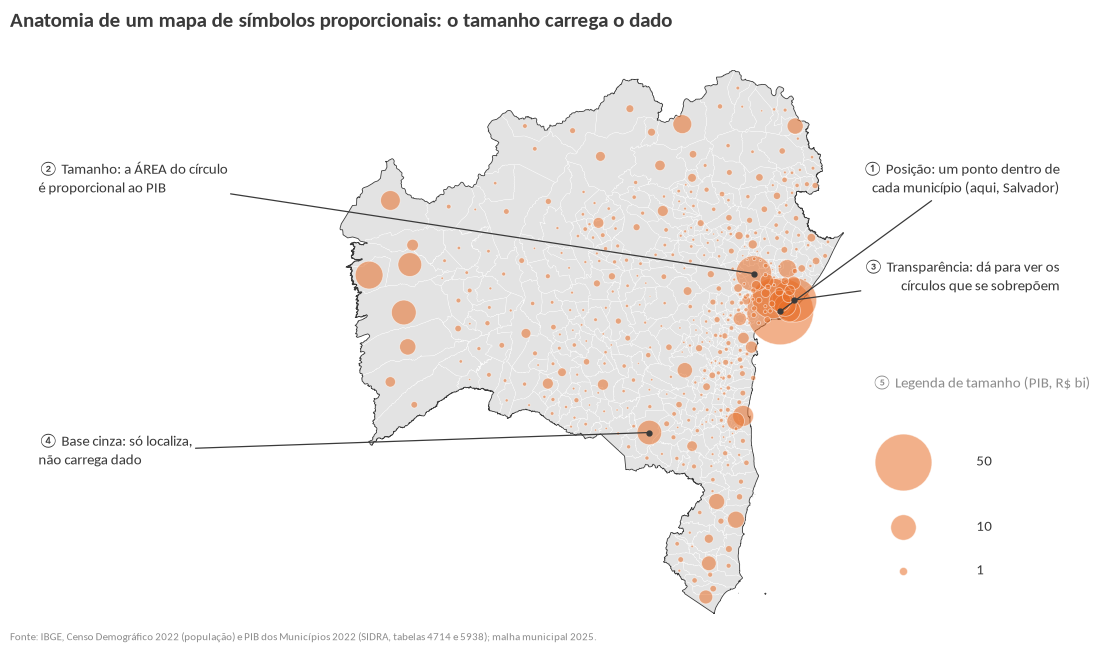

In [4]:
# Figura de anatomia: o mapa de símbolos com os elementos nomeados.
fig, ax = plt.subplots(figsize=(11, 6.4))
base_cinza(ax)
desenhar_simbolos(ax, bahia, bahia["pib_bi"])
ax.set_xlim(minx - 0.62 * (maxx - minx), maxx + 0.45 * (maxx - minx)); ax.set_ylim(miny, maxy)

def nota(texto, alvo, xy_texto, ha):
    p = bahia.loc[bahia["NM_MUN"] == alvo, "pt"].iloc[0]
    ax.annotate(texto, xy=(p.x, p.y), xytext=xy_texto, textcoords="axes fraction", fontsize=11, ha=ha, va="center",
                color=utils.GRAFITE, arrowprops=dict(arrowstyle="-", color=utils.GRAFITE, lw=0.9, shrinkA=0, shrinkB=0), zorder=6)
    ax.plot(p.x, p.y, "o", ms=3.5, color=utils.GRAFITE, zorder=6)

nota("① Posição: um ponto dentro de\ncada município (aqui, Salvador)", "Salvador", (0.99, 0.80), "right")
nota("② Tamanho: a ÁREA do círculo\né proporcional ao PIB", "Feira de Santana", (0.01, 0.80), "left")
nota("③ Transparência: dá para ver os\ncírculos que se sobrepõem", "Camaçari", (0.99, 0.62), "right")
nota("④ Base cinza: só localiza,\nnão carrega dado", "Vitória da Conquista", (0.01, 0.30), "left")
legenda_tamanho(ax, x=0.84, ys=(0.28, 0.16, 0.08), titulo="⑤ Legenda de tamanho (PIB, R$ bi)")
utils.cabecalho(fig, "Anatomia de um mapa de símbolos proporcionais: o tamanho carrega o dado", None)
fig.subplots_adjust(top=0.90, bottom=0.05, left=0.01, right=0.99)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_anatomia.png")
plt.show()

## 2 · Quando usar (e quando não)

**Use** quando a variável é uma **quantidade total** (PIB, população, número de casos): totais dependem do tamanho do lugar, e o símbolo mostra esse tamanho sem pedir que o polígono faça o trabalho. Também funciona quando as unidades têm áreas muito diferentes, porque o símbolo não depende da área, e quando você quer somar a leitura de **duas variáveis** (tamanho e cor).

**Evite** quando:

- a variável é uma **taxa ou razão** (PIB per capita, por exemplo): o coroplético do notebook 01 é a ferramenta; símbolos para taxas confundem "muito" com "muita gente";
- há **muitas unidades pequenas e juntas**: os símbolos se amontoam e escondem uns aos outros (o livro cita Bélgica e Holanda no mapa da Europa);
- o leitor precisa do **valor exato**: círculos são difíceis de comparar com precisão. Para isso, uma tabela ou barras.

A figura mostra por que totais pedem símbolos: no coroplético da população, o tamanho do polígono compete com a cor.

figura salva: figs/fig_004_03_quando_total.png


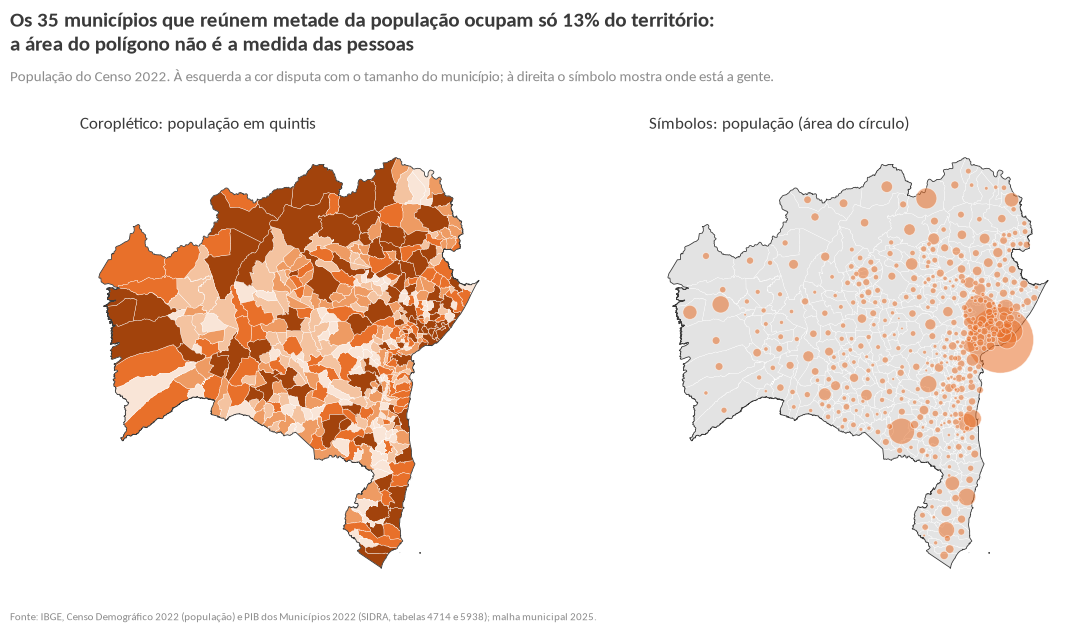

In [5]:
def quintis(v):
    return np.digitize(v, np.quantile(v, [0.2, 0.4, 0.6, 0.8]))

fig, axs = plt.subplots(1, 2, figsize=(11.5, 6.2))
ax = axs[0]
bahia_desenhada.plot(ax=ax, color=[utils.RAMPA[i] for i in quintis(bahia["pop"])], edgecolor="white", linewidth=0.25)
contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.6); utils.sem_eixos(ax)
ax.set_title("Coroplético: população em quintis", fontsize=12, loc="left", color=utils.GRAFITE)

ax = axs[1]
base_cinza(ax)
desenhar_simbolos(ax, bahia, bahia["pop"] / 1e6, escala=lambda v: 2300 * np.asarray(v) / (bahia["pop"].max() / 1e6))
ax.set_title("Símbolos: população (área do círculo)", fontsize=12, loc="left", color=utils.GRAFITE)

fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.06, left=0.01, right=0.99, wspace=0.02)
utils.cabecalho(fig, f"Os {n50} municípios que reúnem metade da população ocupam só {utils.br(area50)}% do território:\na área do polígono não é a medida das pessoas",
             "População do Censo 2022. À esquerda a cor disputa com o tamanho do município; à direita o símbolo mostra onde está a gente.", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_quando_total.png")
plt.show()

## 3 · Como ler (passo a passo)

**Mapa de símbolos (PIB total):**

1. **Título:** diz a conclusão. Aqui, quanto do PIB baiano está em poucos municípios.
2. **Legenda de tamanho:** os três círculos de referência dão a escala. Compare o círculo do mapa com eles, não com o vizinho.
3. **Maior círculo:** é o maior PIB, e os rótulos diretos nomeiam os cinco primeiros.
4. **Círculos sobrepostos:** a transparência deixa ver o que fica atrás; onde há muitos juntos (região de Salvador), o mapa fica denso e o zoom do passo 5.2 ajuda.
5. **Área vazia:** o interior tem círculos pequenos e dispersos. Isso é informação (pouco PIB total), não falta de dado.

**Mapa de pontos (população):**

1. Cada ponto vale **1.000 habitantes**; o texto da legenda diz isso.
2. **Onde os pontos se juntam** há mais gente; onde rareiam, menos.
3. A posição de cada ponto dentro do município é **sorteada**: leia manchas, não pontos individuais.

figura salva: figs/fig_004_03_depois.png


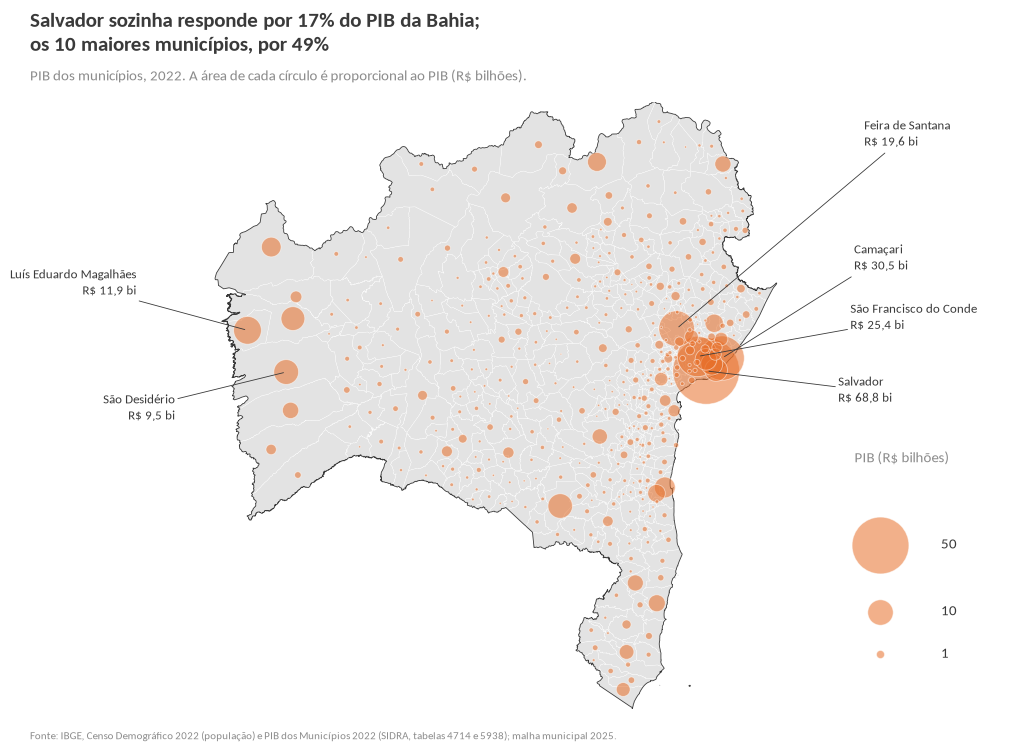

In [6]:
# O mapa final de símbolos
fig, ax = plt.subplots(figsize=(11, 7.4))
base_cinza(ax)
desenhar_simbolos(ax, bahia, bahia["pib_bi"])
estender_direita(ax, 0.40, esquerda=0.14)
legenda_tamanho(ax, ys=(0.27, 0.16, 0.09))

# rótulos diretos nos maiores, com linha-guia; no oceano à direita, onde há espaço
rot = {"Salvador": (95, -14, "left"), "Camaçari": (95, 72, "left"), "São Francisco do Conde": (110, 28, "left"),
       "Feira de Santana": (135, 140, "left"), "Luís Eduardo Magalhães": (-80, 34, "right"), "São Desidério": (-80, -26, "right")}
for nome, (dx, dy, ha) in rot.items():
    p = bahia.loc[bahia["NM_MUN"] == nome, "pt"].iloc[0]
    v = float(bahia.loc[bahia["NM_MUN"] == nome, "pib_bi"].iloc[0])
    ax.annotate(f"{nome}\nR$ {utils.br(v, 1)} bi", xy=(p.x, p.y), xytext=(dx, dy), textcoords="offset points", fontsize=9.5,
                ha=ha, va="center", color=utils.GRAFITE, zorder=7,
                arrowprops=dict(arrowstyle="-", color=utils.GRAFITE, lw=0.6, shrinkA=0, shrinkB=2))
utils.cabecalho(fig, f"Salvador sozinha responde por {utils.br(salvador_pct)}% do PIB da Bahia;\nos 10 maiores municípios, por {utils.br(top10_pct)}%",
             "PIB dos municípios, 2022. A área de cada círculo é proporcional ao PIB (R$ bilhões).", linhas=2)
fig.subplots_adjust(top=utils.topo(fig, 2), bottom=0.05, left=0.01, right=0.99)
REF_PPM = pt_por_m(ax)             # escala do mapa de referência (para o zoom do passo 5.2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_depois.png")
plt.show()

In [7]:
# Densidade de pontos: 1 ponto = 1.000 habitantes, sorteado dentro do município.
def pontos_aleatorios(geom, n, rng):
    shapely.prepare(geom)
    x0, y0, x1, y1 = geom.bounds
    xs, ys = [], []
    while len(xs) < n:
        k = max(2 * (n - len(xs)), 16)
        px, py = rng.uniform(x0, x1, k), rng.uniform(y0, y1, k)
        ok = shapely.contains_xy(geom, px, py)
        xs.extend(px[ok]); ys.extend(py[ok])
    return np.array(xs[:n]), np.array(ys[:n])

def gerar_pontos(g, valor_por_ponto, seed=SEED, no_centroide=False):
    rng = np.random.default_rng(seed)
    px, py = [], []
    for geom, pt, v in zip(g.geometry, g["pt"], g["pop"]):
        x = v / valor_por_ponto
        n = int(np.floor(x) + (rng.random() < x - np.floor(x)))     # arredondamento estocástico: municípios pequenos não somem
        if n == 0:
            continue
        if no_centroide:
            px += [pt.x] * n; py += [pt.y] * n
        else:
            a, b = pontos_aleatorios(geom, n, rng)
            px += list(a); py += list(b)
    return np.array(px), np.array(py)

pts_x, pts_y = gerar_pontos(bahia, 1000)
print(f"{len(pts_x):,} pontos para {bahia['pop'].sum()/1000:,.0f} mil habitantes (1 ponto = 1.000)")

14,148 pontos para 14,142 mil habitantes (1 ponto = 1.000)


figura salva: figs/fig_004_03_pontos.png


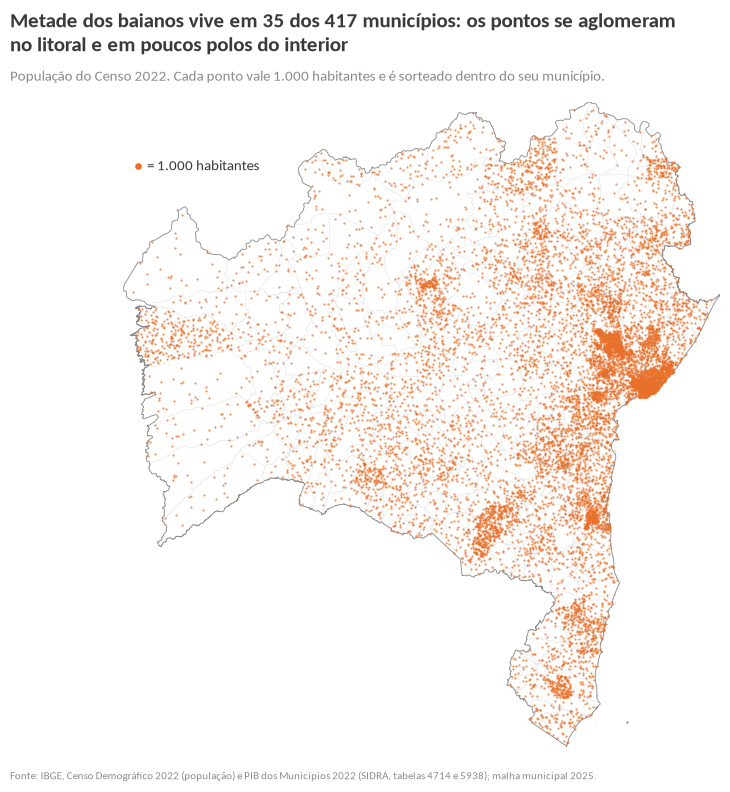

In [8]:
# O mapa final de pontos.
fig, ax = plt.subplots(figsize=(8.4, 7.8))
ax.set_anchor("C")
bahia_desenhada.plot(ax=ax, color="white", edgecolor=utils.CINZA_CLARO, linewidth=0.3, zorder=1)
contorno.boundary.plot(ax=ax, color=utils.CINZA, linewidth=0.6, zorder=2)
ax.scatter(pts_x, pts_y, s=2.6, color=utils.LARANJA, alpha=0.75, linewidths=0, zorder=3)
utils.sem_eixos(ax)
ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
ax.text(0.04, 0.90, "= 1.000 habitantes", transform=ax.transAxes, fontsize=11, ha="left", va="center", color=utils.GRAFITE)
ax.scatter([0.025], [0.90], s=14, color=utils.LARANJA, transform=ax.transAxes, zorder=4, clip_on=False)
ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
utils.cabecalho(fig, f"Metade dos baianos vive em {n50} dos 417 municípios: os pontos se aglomeram\nno litoral e em poucos polos do interior",
             "População do Censo 2022. Cada ponto vale 1.000 habitantes e é sorteado dentro do seu município.", linhas=2)
fig.subplots_adjust(top=utils.topo(fig, 2), bottom=0.05, left=0.01, right=0.99)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_pontos.png")
plt.show()

## 4 · Do livro ao nosso dado

O livro mostra os dois mapas com exemplos diferentes, e o nosso notebook segue a mesma lógica com dados da Bahia:

| Livro | Nosso dado (Bahia, 2022) |
| --- | --- |
| **Símbolos proporcionais:** PIB per capita da Europa, 2017, com círculos e quadrados no lugar da cor; destaca a transparência e a dificuldade de ver os países pequenos e próximos (Bélgica, Holanda) | **PIB total** dos 417 municípios, círculos com área proporcional; transparência e ordem de desenho resolvem as sobreposições |
| **Densidade de pontos:** Censo dos EUA 2010, um ponto por residente (308 milhões), colorido por grupo, sem fronteiras nem rótulos | **População** do Censo 2022, um ponto por 1.000 habitantes, sorteado dentro do município, com fronteiras cinza claro |
| Os pontos desenham o país porque as pessoas se agrupam em cidades e litorais | Os pontos desenham a Bahia: litoral, Salvador e polos do interior aparecem sem precisar de coroplético |

Uma diferença importante: o livro usa **per capita** nos símbolos. Aqui usamos **total**, porque para taxa o coroplético (notebook 01) é a escolha mais direta, e porque queremos mostrar a concentração do PIB, que um mapa de taxa não mostra. Os cinco maiores municípios do ranking mostram o ponto:

In [9]:
t = ord_pib.head(6).copy()
t["PIB (R$ bi)"] = t["pib_bi"].round(1)
t["% do PIB da Bahia"] = part_pib.head(6).round(1).values
t["População"] = t["pop"].astype(int)
t["PIB per capita (R$)"] = t["pib_pc"].round(0).astype(int)
t[["NM_MUN", "PIB (R$ bi)", "% do PIB da Bahia", "População", "PIB per capita (R$)"]].rename(columns={"NM_MUN": "Município"}).reset_index(drop=True)

,Município,PIB (R$ bi),% do PIB da Bahia,População,PIB per capita (R$)
0,Salvador,68.8,17.1,2417678,28442
1,Camaçari,30.5,7.6,300372,101427
2,São Francisco do Conde,25.4,6.3,38733,654785
3,Feira de Santana,19.6,4.9,616272,31845
4,Luís Eduardo Magalhães,11.9,3.0,107909,110639
5,São Desidério,9.5,2.4,32828,289842


## 5 · Boas práticas (com redesenhos "antes → depois")

Quatro decisões fazem o símbolo e o ponto informarem em vez de enfeitar: **como escalar** (área, não raio), **como empilhar** (transparência e ordem), **quanto vale cada ponto** e **onde colocar o ponto**. O mapa "antes" junta os erros; as figuras seguintes corrigem um por vez.

figura salva: figs/fig_004_03_antes.png


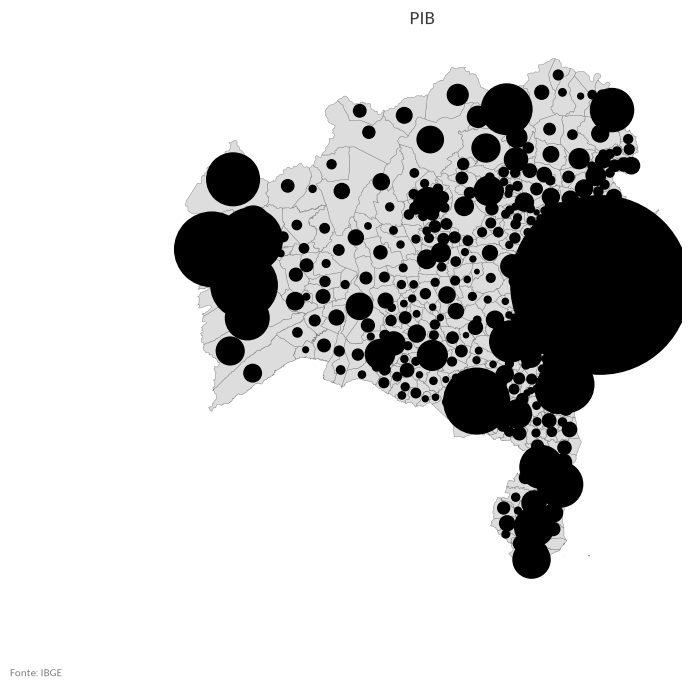

In [10]:
# Antes: raio proporcional ao valor, círculos opacos e pretos, sem legenda, projeção Web Mercator, título genérico.
mer = bahia.copy()
mer["geometry"] = bahia_desenhada.geometry.to_crs(3857).values
mer = mer.set_geometry("geometry")
mer["pt"] = bahia["pt"].set_crs(bahia.crs).to_crs(3857)
fig, ax = plt.subplots(figsize=(8.2, 7.4))
mer.plot(ax=ax, color="#dddddd", edgecolor="gray", linewidth=0.3)
d = mer.sample(frac=1, random_state=1)                      # sem ordenar, círculos grandes podem cobrir os pequenos
ax.scatter(d["pt"].x, d["pt"].y, s=(d["pib_bi"] * 40) ** 1.0 * 6, color="black", edgecolor="black", alpha=1)  # tamanho linear na área exagerada
ax.set_axis_off(); ax.set_aspect("equal")
ax.set_title("PIB", fontsize=14)
fig.text(0.01, 0.01, "Fonte: IBGE", fontsize=8, color="gray")
utils.salvar(fig, "fig_004_03_antes.png")
plt.show()

### 5.1 · Dimensione pela área, não pelo raio

O olho compara **áreas**. Se o raio é proporcional ao valor, a área cresce com o **quadrado** do valor e o maior círculo parece muito mais importante do que é. À esquerda, raio proporcional ao PIB; à direita, área proporcional. O círculo de Salvador é o mesmo nos dois, só muda como os outros são escalados.

figura salva: figs/fig_004_03_a_area_vs_raio.png


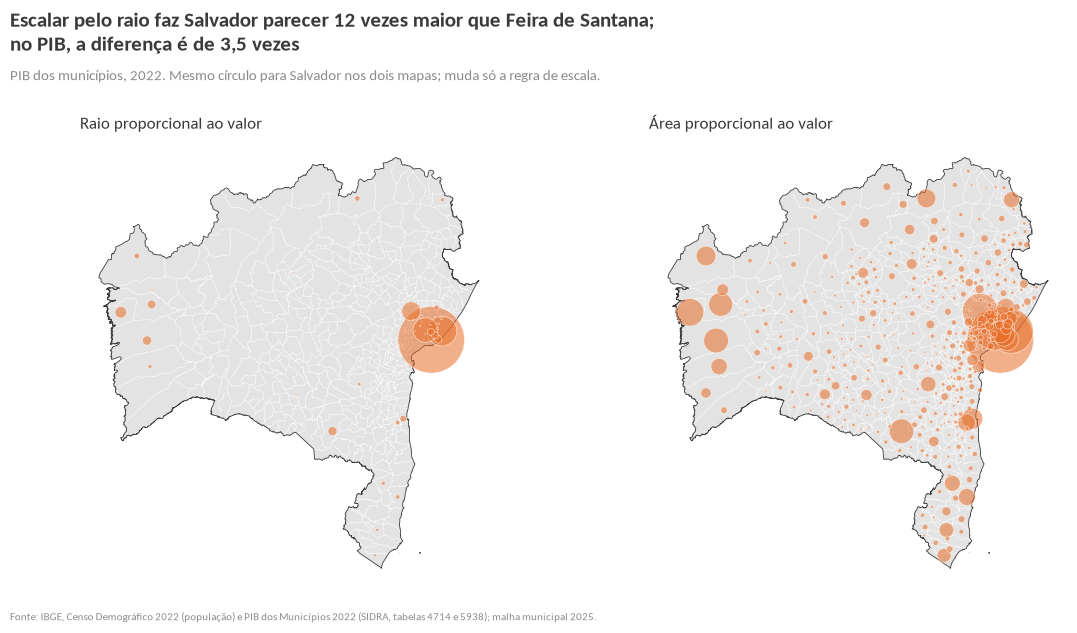

In [11]:
feira = bahia.loc[bahia["NM_MUN"] == "Feira de Santana", "pib_bi"].iloc[0]
salv = bahia.loc[bahia["NM_MUN"] == "Salvador", "pib_bi"].iloc[0]
razao = salv / feira

fig, axs = plt.subplots(1, 2, figsize=(11.5, 6.2))
for ax, escala, titulo in [(axs[0], lambda v: S_MAX * (np.asarray(v) / VMAX) ** 2, "Raio proporcional ao valor"),
                           (axs[1], area_simbolo, "Área proporcional ao valor")]:
    base_cinza(ax)
    desenhar_simbolos(ax, bahia, bahia["pib_bi"], escala=escala)
    ax.set_title(titulo, fontsize=12, loc="left", color=utils.GRAFITE)
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.06, left=0.01, right=0.99, wspace=0.02)
utils.cabecalho(fig, f"Escalar pelo raio faz Salvador parecer {utils.br(razao ** 2)} vezes maior que Feira de Santana;\nno PIB, a diferença é de {utils.br(razao, 1)} vezes",
             "PIB dos municípios, 2022. Mesmo círculo para Salvador nos dois mapas; muda só a regra de escala.", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_a_area_vs_raio.png")
plt.show()

### 5.2 · Transparência e ordem de desenho

Onde os símbolos se sobrepõem (aqui, a região metropolitana de Salvador), círculos opacos escondem uns aos outros. A correção tem duas partes: **transparência** (o livro destaca isso) e **desenhar os maiores primeiro**, para que os menores fiquem por cima e continuem visíveis. Abaixo, um zoom na região.

figura salva: figs/fig_004_03_b_transparencia.png


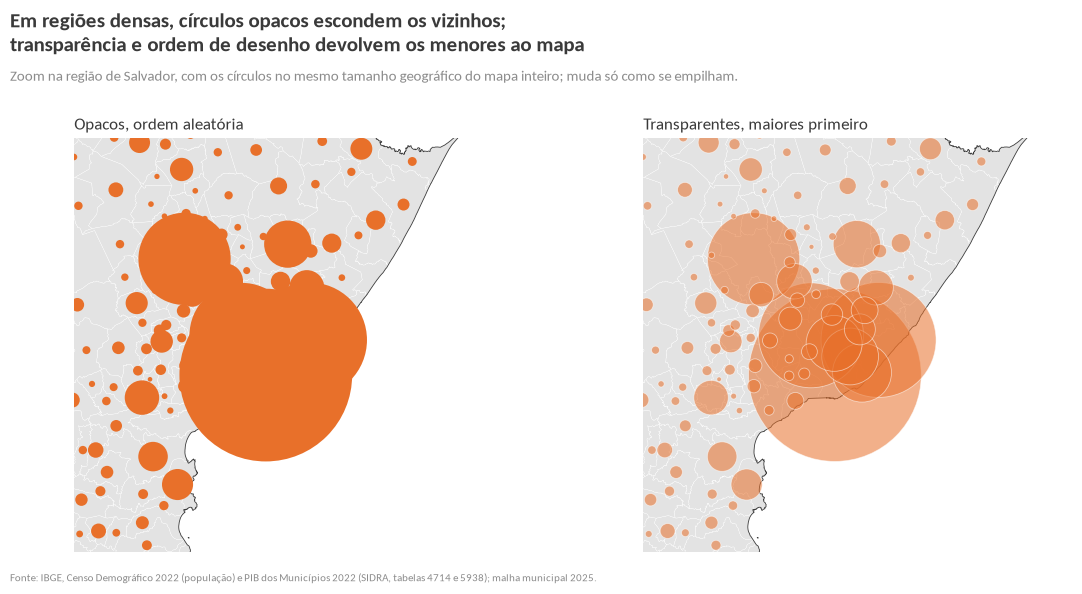

In [12]:
rms = bahia[bahia["NM_MUN"].isin(["Salvador", "Lauro de Freitas", "Camaçari", "Simões Filho", "Candeias", "São Francisco do Conde",
                                  "Dias d'Ávila", "Pojuca", "Mata de São João", "Madre de Deus", "São Sebastião do Passé", "Vera Cruz", "Itaparica"])]
zx0, zy0, zx1, zy1 = rms.total_bounds
mx, my = 0.9 * (zx1 - zx0), 0.9 * (zy1 - zy0)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 5.8))
for ax, depois in zip(axs, [False, True]):
    base_cinza(ax, g=bahia)
    d = bahia.sample(frac=1, random_state=3) if not depois else bahia
    ax.set_xlim(zx0 - mx, zx1 + mx); ax.set_ylim(zy0 - my, zy1 + my)
    fator = (pt_por_m(ax) / REF_PPM) ** 2          # mantém o círculo do tamanho geográfico que tinha no mapa inteiro
    desenhar_simbolos(ax, d, d["pib_bi"], alpha=0.55 if depois else 1.0, borda="white" if depois else None, ordem=depois,
                      escala=lambda v, f=fator: area_simbolo(v) * f)
    ax.set_title("Opacos, ordem aleatória" if not depois else "Transparentes, maiores primeiro", fontsize=12, loc="left", color=utils.GRAFITE)
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.06, left=0.01, right=0.99, wspace=0.02)
fig.canvas.draw()
utils.cabecalho(fig, "Em regiões densas, círculos opacos escondem os vizinhos;\ntransparência e ordem de desenho devolvem os menores ao mapa",
             "Zoom na região de Salvador, com os círculos no mesmo tamanho geográfico do mapa inteiro; muda só como se empilham.", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_b_transparencia.png")
plt.show()

### 5.3 · Escolha o valor de cada ponto

No mapa de pontos, o **valor de um ponto** é a decisão principal. Poucos pontos (cada um vale muito) deixam o interior vazio; muitos pontos (cada um vale pouco) viram uma mancha onde não se distingue nada. Comparamos três valores com a mesma semente.

figura salva: figs/fig_004_03_c_valor_ponto.png


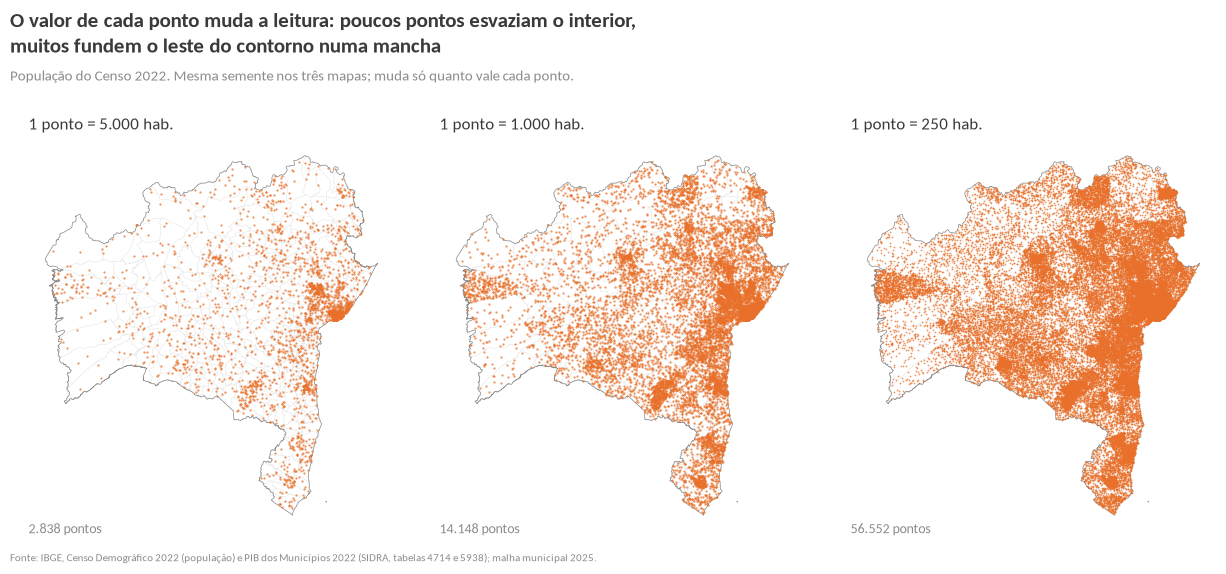

In [13]:
valores = [5000, 1000, 250]
fig, axs = plt.subplots(1, 3, figsize=(12.5, 5.6))
contagens = []
for ax, vp in zip(axs, valores):
    x, y = gerar_pontos(bahia, vp)
    contagens.append(len(x))
    bahia_desenhada.plot(ax=ax, color="white", edgecolor=utils.CINZA_CLARO, linewidth=0.25, zorder=1)
    contorno.boundary.plot(ax=ax, color=utils.CINZA, linewidth=0.5, zorder=2)
    ax.scatter(x, y, s=2.6 if vp >= 1000 else 1.6, color=utils.LARANJA, alpha=0.75, linewidths=0, zorder=3)
    utils.sem_eixos(ax)
    ax.set_title(f"1 ponto = {utils.br(vp)} hab.", fontsize=12, loc="left", color=utils.GRAFITE)
    ax.text(0.0, 0.0, f"{utils.br(len(x))} pontos", transform=ax.transAxes, fontsize=10, color=utils.CINZA)
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.06, left=0.01, right=0.99, wspace=0.02)
utils.cabecalho(fig, "O valor de cada ponto muda a leitura: poucos pontos esvaziam o interior,\nmuitos fundem o leste do contorno numa mancha",
             "População do Censo 2022. Mesma semente nos três mapas; muda só quanto vale cada ponto.", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_c_valor_ponto.png")
plt.show()

**Decisão adotada:** 1 ponto = 1.000 habitantes (cerca de 14 mil pontos). Mantém o interior visível e ainda deixa o litoral legível.

### 5.4 · Sorteie os pontos dentro do município

Sem o endereço de cada pessoa, cada ponto precisa de uma posição. Empilhar todos no centro do município cria "bolas" que não existem: um ponto sobre o outro vira um só. Sortear dentro do polígono respeita a geografia (e a semente fixa torna o resultado reproduzível). O livro diz o mesmo: sem coordenadas exatas, os símbolos vão em posição aleatória dentro da área.

figura salva: figs/fig_004_03_d_posicao.png


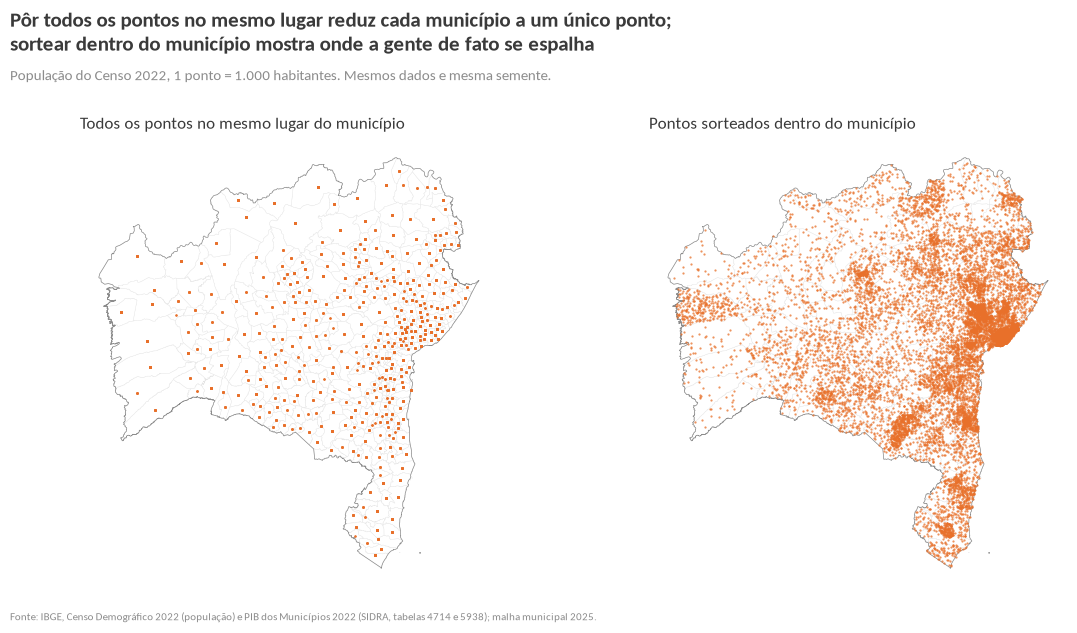

In [14]:
x_c, y_c = gerar_pontos(bahia, 1000, no_centroide=True)
x_a, y_a = gerar_pontos(bahia, 1000)
fig, axs = plt.subplots(1, 2, figsize=(11.5, 6.2))
for ax, (x, y), titulo in [(axs[0], (x_c, y_c), "Todos os pontos no mesmo lugar do município"), (axs[1], (x_a, y_a), "Pontos sorteados dentro do município")]:
    bahia_desenhada.plot(ax=ax, color="white", edgecolor=utils.CINZA_CLARO, linewidth=0.25, zorder=1)
    contorno.boundary.plot(ax=ax, color=utils.CINZA, linewidth=0.5, zorder=2)
    ax.scatter(x, y, s=2.6, color=utils.LARANJA, alpha=0.75, linewidths=0, zorder=3)
    utils.sem_eixos(ax)
    ax.set_title(titulo, fontsize=12, loc="left", color=utils.GRAFITE)
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.06, left=0.01, right=0.99, wspace=0.02)
utils.cabecalho(fig, "Pôr todos os pontos no mesmo lugar reduz cada município a um único ponto;\nsortear dentro do município mostra onde a gente de fato se espalha",
             "População do Censo 2022, 1 ponto = 1.000 habitantes. Mesmos dados e mesma semente.", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_d_posicao.png")
plt.show()

### 5.5 · O redesenho completo

O par `fig_004_03_antes.png` e `fig_004_03_depois.png` resume o bloco para símbolos: do raio linear, círculos pretos e opacos, sem legenda e em Mercator, para **área proporcional, transparência, maiores primeiro, legenda de tamanho, rótulos diretos nos maiores, projeção de área igual e título que diz a conclusão**. Para pontos, `fig_004_03_pontos.png` aplica as decisões 5.3 e 5.4.

## 6 · Alternativas

Se a pergunta é *quanto se concentra em quantos municípios?*, nem símbolos nem pontos respondem com precisão. Opções:

| Alternativa | O que ganha | O que perde |
| --- | --- | --- |
| **Curva acumulada** (abaixo) | responde "quantos municípios reúnem metade?" com um número exato | perde a localização |
| **Barras ordenadas** (abaixo) | valor exato e comparação direta dos maiores | perde a localização e os pequenos |
| **Coroplético de taxa** (notebook 01) | mostra a taxa, não o total | volta o problema da área |
| **Cartograma** (notebook 02) | devolve o peso à população, mantendo o mapa | o mapa deixa de ser familiar |
| **Mapa de calor** | suaviza os pontos em uma superfície contínua | perde as fronteiras e cria uma superfície que o dado não tem |

A figura combina as duas primeiras: barras para os maiores, curva para a concentração.

figura salva: figs/fig_004_03_e_alternativas.png


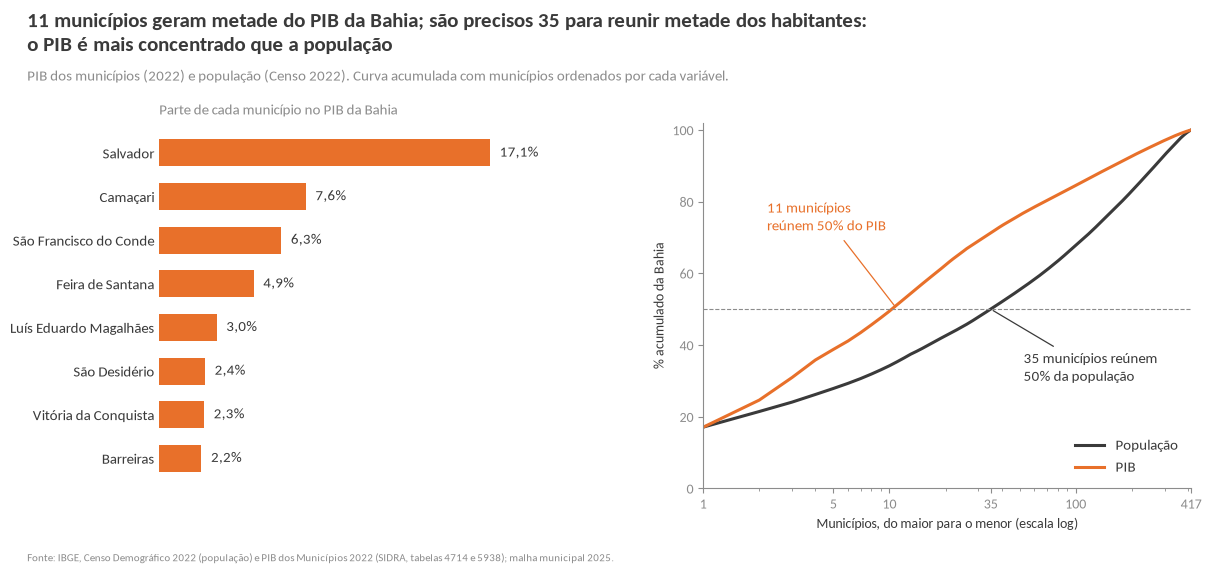

In [15]:
x = np.arange(1, len(bahia) + 1)
cum_pib = ord_pib["pib_bi"].cumsum() / ord_pib["pib_bi"].sum() * 100
n50_pib = int((cum_pib < 50).sum() + 1)

fig, (axb, axc) = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.35})
top = ord_pib.head(8).iloc[::-1]
axb.barh(top["NM_MUN"], part_pib.head(8).iloc[::-1], color=utils.LARANJA, height=0.62)
for i, v in enumerate(part_pib.head(8).iloc[::-1]):
    axb.text(v + 0.5, i, f"{utils.br(v, 1)}%", va="center", fontsize=10.5, color=utils.GRAFITE)
axb.set_xticks([]); axb.set_xlim(0, part_pib.max() * 1.18)
axb.tick_params(axis="y", length=0, labelsize=10.5, colors=utils.GRAFITE)
for s in ("left", "bottom"): axb.spines[s].set_visible(False)
axb.set_title("Parte de cada município no PIB da Bahia", fontsize=11, loc="left", color=utils.CINZA)

axc.plot(x, cum_pop, color=utils.GRAFITE, lw=2.2, label="População")
axc.plot(x, cum_pib, color=utils.LARANJA, lw=2.2, label="PIB")
axc.axhline(50, color=utils.CINZA, lw=0.8, ls="--")
axc.set_xscale("log"); axc.set_ylim(0, 102); axc.set_xlim(1, 417)
axc.set_xticks([1, 5, 10, 35, 100, 417]); axc.set_xticklabels(["1", "5", "10", "35", "100", "417"])
axc.set_xlabel("Municípios, do maior para o menor (escala log)"); axc.set_ylabel("% acumulado da Bahia")
axc.annotate(f"{n50_pib} municípios\nreúnem 50% do PIB", xy=(n50_pib, 50), xytext=(n50_pib * 0.2, 72), fontsize=10.5, color=utils.LARANJA,
             arrowprops=dict(arrowstyle="-", color=utils.LARANJA, lw=0.9))
axc.annotate(f"{n50} municípios reúnem\n50% da população", xy=(n50, 50), xytext=(n50 * 1.5, 30), fontsize=10.5, color=utils.GRAFITE,
             arrowprops=dict(arrowstyle="-", color=utils.GRAFITE, lw=0.9))
axc.legend(frameon=False, loc="lower right", fontsize=10.5)
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.2), bottom=0.14, left=0.12, right=0.98)
utils.cabecalho(fig, f"{n50_pib} municípios geram metade do PIB da Bahia; são precisos {n50} para reunir metade dos habitantes:\no PIB é mais concentrado que a população",
             "PIB dos municípios (2022) e população (Censo 2022). Curva acumulada com municípios ordenados por cada variável.", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_03_e_alternativas.png")
plt.show()

## O que levar deste notebook

- **Símbolos para totais, coroplético para taxas.**
- **Área, não raio**, e uma legenda de tamanho sempre visível.
- **Transparência e ordem de desenho** para sobreposição.
- **Pontos:** escolha o valor de cada ponto olhando o resultado e **sorteie dentro da unidade**, com semente fixa.
- **Pergunte antes se o mapa é a melhor forma:** uma curva acumulada responde "quantos?" melhor que qualquer mapa.